In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

L_lswt = 64
L_test = 16
J_lswt = 1.0
Jz_lswt = 1.0
q0_lswt = np.pi / 4
D_lswt = J_lswt * np.tan(q0_lswt)
J2_lswt = J_lswt / (4 * np.cos(q0_lswt))
B_z_lswt = 0.0

ex_lswt = np.array([1.0, 0.0, 0.0])
output_dir = Path("lswt_3d_results")
output_dir.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "savefig.dpi": 400
})

print("LSWT lattice:", (L_lswt, L_lswt, L_lswt))
print("Numerical validation lattice:", (L_test, L_test, L_test))
print("J:", J_lswt, "Jz:", Jz_lswt, "D:", D_lswt, "J2:", J2_lswt)
print("Magnetic spiral wavelength:", 2 * np.pi / q0_lswt)

LSWT lattice: (64, 64, 64)
Numerical validation lattice: (16, 16, 16)
J: 1.0 Jz: 1.0 D: 0.9999999999999999 J2: 0.35355339059327373
Magnetic spiral wavelength: 8.0


In [2]:
def normalize_spins(spins):
    return spins / np.linalg.norm(spins, axis=-1, keepdims=True)


def effective_field_3d(spins, model):
    xp = np.roll(spins, -1, axis=0)
    xm = np.roll(spins, 1, axis=0)
    yp = np.roll(spins, -1, axis=1)
    ym = np.roll(spins, 1, axis=1)
    zp = np.roll(spins, -1, axis=2)
    zm = np.roll(spins, 1, axis=2)

    field = J_lswt * (xp + xm + yp + ym)
    field += Jz_lswt * (zp + zm)

    if model == "dmi":
        field += D_lswt * np.cross(xp - xm, ex_lswt)
    elif model == "frustration":
        field -= J2_lswt * (
            np.roll(spins, -2, axis=0)
            + np.roll(spins, 2, axis=0)
        )
    else:
        raise ValueError(model)

    field[..., 2] += B_z_lswt
    return field


def spin_rhs_3d(spins, model):
    return -np.cross(spins, effective_field_3d(spins, model))


def spin_energy_3d(spins, model):
    xp = np.roll(spins, -1, axis=0)
    yp = np.roll(spins, -1, axis=1)
    zp = np.roll(spins, -1, axis=2)

    E = -J_lswt * np.sum(spins * (xp + yp))
    E -= Jz_lswt * np.sum(spins * zp)

    if model == "dmi":
        E += D_lswt * np.sum(spins * np.cross(ex_lswt, xp))
    elif model == "frustration":
        E += J2_lswt * np.sum(
            spins * np.roll(spins, -2, axis=0)
        )
    else:
        raise ValueError(model)

    E -= B_z_lswt * np.sum(spins[..., 2])
    return E

In [3]:
def lswt_coefficients_3d(kx, ky, kz, model):
    cx = np.cos(kx)
    cy = np.cos(ky)
    cz = np.cos(kz)
    cq = np.cos(q0_lswt)

    if model == "dmi":
        lam = (
            2 * J_lswt * (cq + 1)
            + 2 * Jz_lswt
            + 2 * D_lswt * np.sin(q0_lswt)
        )
        A = lam - 2 * J_lswt * (cx + cy) - 2 * Jz_lswt * cz
        B = lam - 2 * (
            (J_lswt * cq + D_lswt * np.sin(q0_lswt)) * cx
            + J_lswt * cy + Jz_lswt * cz
        )
    elif model == "frustration":
        lam = (
            2 * J_lswt * (cq + 1)
            + 2 * Jz_lswt
            - 2 * J2_lswt * np.cos(2 * q0_lswt)
        )
        A = (
            lam - 2 * J_lswt * (cx + cy)
            - 2 * Jz_lswt * cz
            + 2 * J2_lswt * np.cos(2 * kx)
        )
        B = (
            lam - 2 * J_lswt * (cq * cx + cy)
            - 2 * Jz_lswt * cz
            + 2 * J2_lswt * np.cos(2 * q0_lswt) * np.cos(2 * kx)
        )
    else:
        raise ValueError(model)

    return A, B


def lswt_frequency_3d(kx, ky, kz, model):
    A, B = lswt_coefficients_3d(kx, ky, kz, model)
    return np.sqrt(np.maximum(A * B, 0.0))


k_lswt = 2 * np.pi * np.fft.fftfreq(L_lswt)
kx_grid, ky_grid, kz_grid = np.meshgrid(
    k_lswt, k_lswt, k_lswt, indexing="ij"
)

omega_dmi = lswt_frequency_3d(kx_grid, ky_grid, kz_grid, "dmi")
omega_frustration = lswt_frequency_3d(kx_grid, ky_grid, kz_grid, "frustration")

print("Dispersion grid:", omega_dmi.shape)
print("DMI-x energy range:", omega_dmi.min(), omega_dmi.max())
print("Frustration energy range:", omega_frustration.min(), omega_frustration.max())
print("DMI-x at (pi/2, pi/4, 0):", lswt_frequency_3d(np.pi / 2, np.pi / 4, 0, "dmi"))
print("Frustration at (pi/2, pi/4, 0):", lswt_frequency_3d(np.pi / 2, np.pi / 4, 0, "frustration"))
print("DMI-x at (pi/2, pi/4, pi/4):", lswt_frequency_3d(np.pi / 2, np.pi / 4, np.pi / 4, "dmi"))
print("Frustration at (pi/2, pi/4, pi/4):", lswt_frequency_3d(np.pi / 2, np.pi / 4, np.pi / 4, "frustration"))

Dispersion grid: (64, 64, 64)
DMI-x energy range: 0.0 13.236161055717526
Frustration energy range: 2.291921532797786e-09 11.456650208326124
DMI-x at (pi/2, pi/4, 0): 3.414213562373094
Frustration at (pi/2, pi/4, 0): 1.6080380709507174
DMI-x at (pi/2, pi/4, pi/4): 3.999999999999999
Frustration at (pi/2, pi/4, pi/4): 2.2040563459832527


In [4]:
coords = np.indices((L_test, L_test, L_test))
phi_test = q0_lswt * coords[0]
spiral0 = np.stack((
    np.zeros_like(phi_test),
    np.cos(phi_test),
    np.sin(phi_test)
), axis=-1)

tangent_a = np.zeros_like(spiral0)
tangent_a[..., 0] = 1.0

tangent_b = np.stack((
    np.zeros_like(phi_test),
    -np.sin(phi_test),
    np.cos(phi_test)
), axis=-1)


def numerical_dynamical_matrix_3d(model, epsilon=1e-5):
    matrix = np.zeros((L_test, L_test, L_test, 2, 2), dtype=np.complex128)

    for column, tangent in enumerate((tangent_a, tangent_b)):
        impulse = np.zeros_like(spiral0)
        impulse[0, 0, 0] = tangent[0, 0, 0]

        plus = normalize_spins(spiral0 + epsilon * impulse)
        minus = normalize_spins(spiral0 - epsilon * impulse)

        derivative = (
            spin_rhs_3d(plus, model)
            - spin_rhs_3d(minus, model)
        ) / (2 * epsilon)

        derivative_a = np.sum(derivative * tangent_a, axis=-1)
        derivative_b = np.sum(derivative * tangent_b, axis=-1)

        matrix[..., 0, column] = np.fft.fftn(derivative_a)
        matrix[..., 1, column] = np.fft.fftn(derivative_b)

    return matrix


k_test_grid = 2 * np.pi * np.fft.fftfreq(L_test)
kx_test_grid, ky_test_grid, kz_test_grid = np.meshgrid(
    k_test_grid, k_test_grid, k_test_grid, indexing="ij"
)

for model in ("dmi", "frustration"):
    torque = np.max(np.abs(spin_rhs_3d(spiral0, model)))
    matrix = numerical_dynamical_matrix_3d(model)
    eigvals = np.linalg.eigvals(matrix)
    omega_numeric = np.max(np.abs(np.imag(eigvals)), axis=-1)
    omega_analytic = lswt_frequency_3d(
        kx_test_grid, ky_test_grid, kz_test_grid, model
    )

    error = np.max(np.abs(omega_numeric - omega_analytic))
    energy_per_spin = spin_energy_3d(spiral0, model) / (L_test ** 3)

    print(model, "equilibrium torque:", torque)
    print(model, "energy/spin:", energy_per_spin)
    print(model, "3D linearization max error:", error)

    assert torque < 1e-10
    assert error < 5e-6

dmi equilibrium torque: 3.552713678800501e-15
dmi energy/spin: -3.414213562373095
dmi 3D linearization max error: 1.6411469468819202e-06
frustration equilibrium torque: 1.7763568394002505e-15
frustration energy/spin: -2.7071067811865475
frustration 3D linearization max error: 4.416475665128545e-07


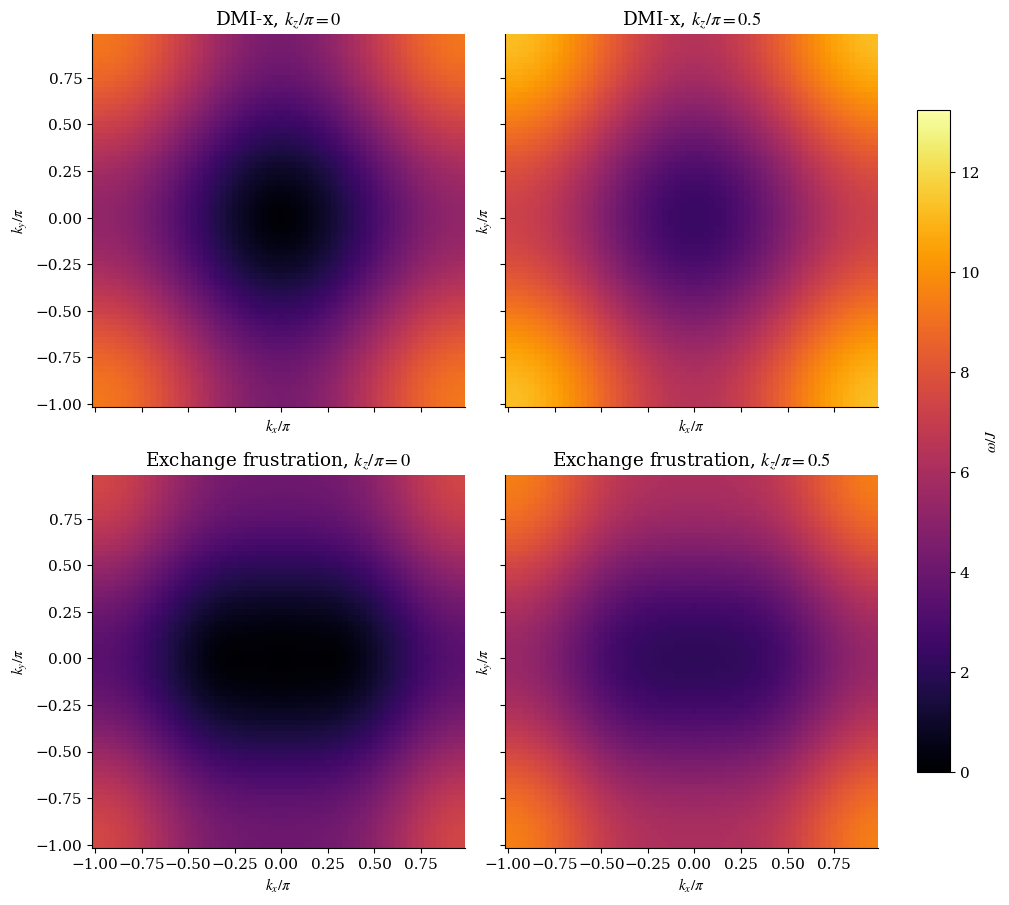

In [5]:
ks = np.fft.fftshift(k_lswt)
wd = np.fft.fftshift(omega_dmi, axes=(0, 1, 2))
wf = np.fft.fftshift(omega_frustration, axes=(0, 1, 2))
vmax = max(wd.max(), wf.max())

fig, axes = plt.subplots(
    2, 2, figsize=(10, 9), sharex=True, sharey=True,
    constrained_layout=True
)

for row, (frequency, model_name) in enumerate((
    (wd, "DMI-x"), (wf, "Exchange frustration")
)):
    for column, kz_value in enumerate((0.0, np.pi / 2)):
        kz_idx = np.argmin(np.abs(ks - kz_value))
        ax = axes[row, column]
        im = ax.pcolormesh(
            ks / np.pi, ks / np.pi, frequency[:, :, kz_idx].T,
            shading="auto", cmap="inferno", vmin=0, vmax=vmax
        )
        ax.set_title(rf"{model_name}, $k_z/\pi={kz_value / np.pi:g}$")
        ax.set_xlabel(r"$k_x/\pi$")
        ax.set_ylabel(r"$k_y/\pi$")
        ax.set_aspect("equal")

fig.colorbar(im, ax=axes, label=r"$\omega/J$", shrink=0.8)
fig.savefig(output_dir / "lswt_3d_kz_slices.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_3d_kz_slices.png", dpi=350, bbox_inches="tight")
plt.show()

DMI-x points near iso-frequency: 2150
Exchange frustration points near iso-frequency: 3622


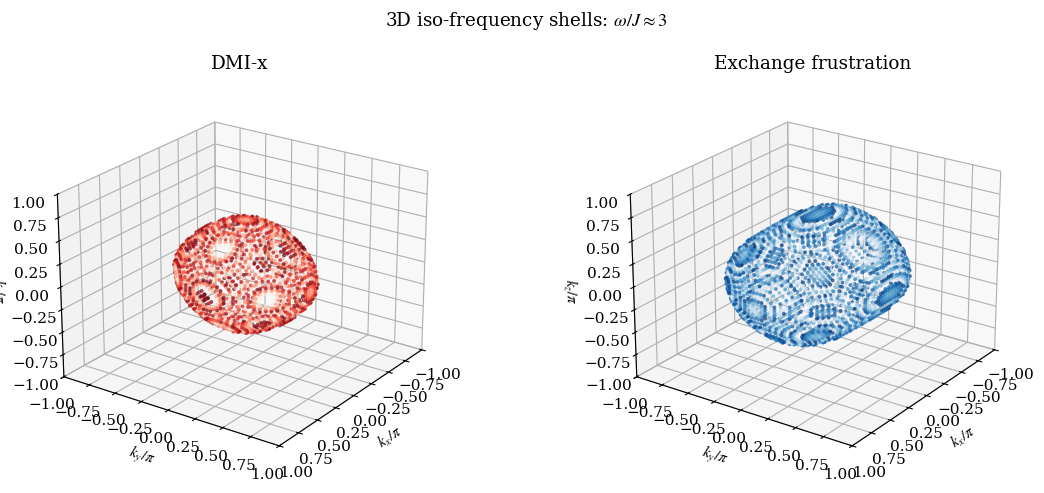

In [6]:
iso_omega = 3.0
iso_width = 0.075

fig = plt.figure(figsize=(12, 5))

for index, (frequency, model_name, cmap) in enumerate((
    (wd, "DMI-x", "Reds"),
    (wf, "Exchange frustration", "Blues")
), start=1):
    indices = np.argwhere(np.abs(frequency - iso_omega) < iso_width)
    stride = max(1, int(np.ceil(len(indices) / 4500)))
    indices = indices[::stride]

    ax = fig.add_subplot(1, 2, index, projection="3d")
    ax.scatter(
        ks[indices[:, 0]] / np.pi,
        ks[indices[:, 1]] / np.pi,
        ks[indices[:, 2]] / np.pi,
        c=frequency[indices[:, 0], indices[:, 1], indices[:, 2]],
        cmap=cmap, vmin=iso_omega-iso_width, vmax=iso_omega+iso_width,
        s=3.5, alpha=0.58, rasterized=True
    )
    ax.set_title(model_name)
    ax.set_xlabel(r"$k_x/\pi$")
    ax.set_ylabel(r"$k_y/\pi$")
    ax.set_zlabel(r"$k_z/\pi$")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-1, 1)
    ax.view_init(elev=23, azim=35)
    print(model_name, "points near iso-frequency:", len(indices))

fig.suptitle(rf"3D iso-frequency shells: $\omega/J\approx{iso_omega:g}$")
fig.tight_layout()
fig.savefig(output_dir / "lswt_3d_isoenergy.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_3d_isoenergy.png", dpi=350, bbox_inches="tight")
plt.show()

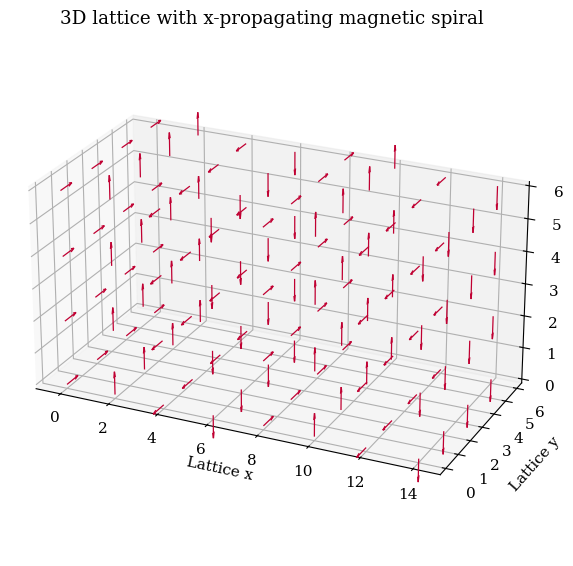

In [7]:
fig = plt.figure(figsize=(8.5, 5.8))
ax = fig.add_subplot(111, projection="3d")

gx, gy, gz = np.meshgrid(
    np.arange(0, 16, 2),
    np.arange(0, 8, 2),
    np.arange(0, 8, 2),
    indexing="ij"
)

ax.quiver(
    gx, gy, gz,
    np.zeros_like(gx),
    np.cos(q0_lswt * gx),
    np.sin(q0_lswt * gx),
    color="#C00032", length=0.72,
    normalize=True, linewidth=0.9, arrow_length_ratio=0.27
)

ax.set_xlabel("Lattice x")
ax.set_ylabel("Lattice y")
ax.set_zlabel("Lattice z")
ax.set_title("3D lattice with x-propagating magnetic spiral")
ax.set_box_aspect((2, 1, 1))
ax.view_init(elev=24, azim=-65)
fig.tight_layout()
fig.savefig(output_dir / "spiral_3d_lattice.pdf", bbox_inches="tight")
fig.savefig(output_dir / "spiral_3d_lattice.png", dpi=350, bbox_inches="tight")
plt.show()

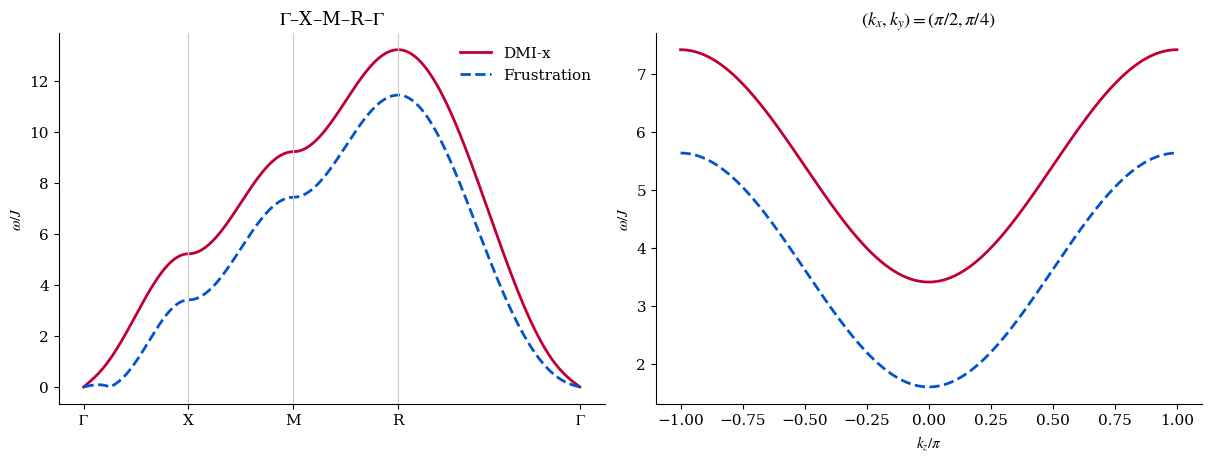

In [8]:
nodes = np.array([
    [0.0, 0.0, 0.0],
    [np.pi, 0.0, 0.0],
    [np.pi, np.pi, 0.0],
    [np.pi, np.pi, np.pi],
    [0.0, 0.0, 0.0]
])
node_labels = [r"$\Gamma$", "X", "M", "R", r"$\Gamma$"]

path = []
path_distance = []
ticks = [0.0]
arc_length = 0.0

for start, end in zip(nodes[:-1], nodes[1:]):
    t = np.linspace(0, 1, 150, endpoint=False)
    path.append(start + t[:, None] * (end - start))
    path_distance.append(arc_length + t * np.linalg.norm(end - start))
    arc_length += np.linalg.norm(end - start)
    ticks.append(arc_length)

path = np.vstack(path + [nodes[-1:]])
path_distance = np.concatenate(path_distance + [[arc_length]])

kz_line = np.linspace(-np.pi, np.pi, 1001)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for model, color, style, name in (
    ("dmi", "#C00032", "-", "DMI-x"),
    ("frustration", "#0055CC", "--", "Frustration")
):
    axes[0].plot(
        path_distance,
        lswt_frequency_3d(path[:, 0], path[:, 1], path[:, 2], model),
        color=color, linestyle=style, lw=2, label=name
    )
    axes[1].plot(
        kz_line / np.pi,
        lswt_frequency_3d(np.pi/2, np.pi/4, kz_line, model),
        color=color, linestyle=style, lw=2, label=name
    )

for tick in ticks[1:-1]:
    axes[0].axvline(tick, color="0.8", lw=0.8)

axes[0].set_xticks(ticks, node_labels)
axes[0].set_ylabel(r"$\omega/J$")
axes[0].set_title(r"$\Gamma$–X–M–R–$\Gamma$")
axes[0].legend(frameon=False)

axes[1].set_xlabel(r"$k_z/\pi$")
axes[1].set_ylabel(r"$\omega/J$")
axes[1].set_title(r"$(k_x,k_y)=(\pi/2,\pi/4)$")

fig.savefig(output_dir / "lswt_3d_paths.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_3d_paths.png", dpi=350, bbox_inches="tight")
plt.show()

In [9]:
def rk4_step_3d(spins, dt, model):
    k1 = spin_rhs_3d(spins, model)
    k2 = spin_rhs_3d(normalize_spins(spins + 0.5 * dt * k1), model)
    k3 = spin_rhs_3d(normalize_spins(spins + 0.5 * dt * k2), model)
    k4 = spin_rhs_3d(normalize_spins(spins + dt * k3), model)

    return normalize_spins(
        spins + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    )


def simulate_spin_wave_3d(model, kx, ky, kz, dt=0.025, steps=2048, amplitude=0.0005):
    wave = np.cos(
        kx * coords[0] + ky * coords[1] + kz * coords[2]
    )
    spins = normalize_spins(
        spiral0 + amplitude * wave[..., None] * tangent_a
    )

    energy_initial = spin_energy_3d(spins, model)
    signal = np.empty(steps)

    for n in range(steps):
        signal[n] = 2 * np.mean(spins[..., 0] * wave)
        spins = rk4_step_3d(spins, dt, model)

    time = dt * np.arange(steps)
    frequencies = 2 * np.pi * np.fft.rfftfreq(steps, dt)
    power = np.abs(np.fft.rfft(
        (signal - signal.mean()) * np.hanning(steps)
    )) ** 2

    peak = np.argmax(power[1:]) + 1
    left, middle, right = np.log(power[peak-1:peak+2] + 1e-35)
    correction = 0.5 * (left - right) / (left - 2 * middle + right)
    measured = (peak + correction) * (frequencies[1] - frequencies[0])

    drift = spin_energy_3d(spins, model) - energy_initial
    norm_error = np.max(np.abs(np.linalg.norm(spins, axis=-1) - 1))

    return time, signal, frequencies, power, measured, drift, norm_error


kx_test = np.pi / 2
ky_test = np.pi / 4
kz_test = np.pi / 4

results_dmi = simulate_spin_wave_3d("dmi", kx_test, ky_test, kz_test)
results_fr = simulate_spin_wave_3d("frustration", kx_test, ky_test, kz_test)

for model, result in (("dmi", results_dmi), ("frustration", results_fr)):
    theory = lswt_frequency_3d(kx_test, ky_test, kz_test, model)
    print(f"{model:12s} LSWT={theory:.6f}  3D dynamics={result[4]:.6f}  error={abs(result[4]-theory):.6f}")
    print(f"{model:12s} energy drift={result[5]:.3e}  norm error={result[6]:.3e}")

dmi          LSWT=4.000000  3D dynamics=3.998557  error=0.001443
dmi          energy drift=-2.909e-08  norm error=1.110e-16
frustration  LSWT=2.204056  3D dynamics=2.203659  error=0.000397
frustration  energy drift=-3.838e-10  norm error=1.110e-16


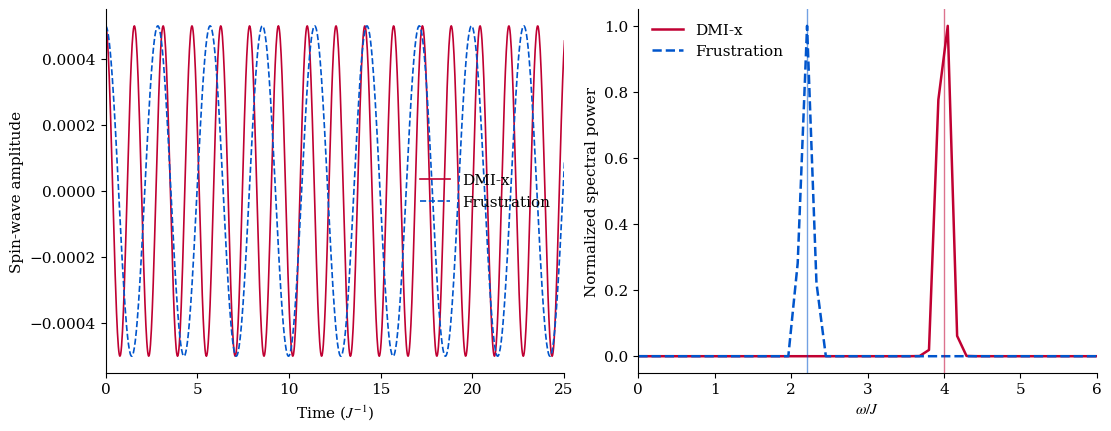

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

for model, result, color, style in (
    ("DMI-x", results_dmi, "#C00032", "-"),
    ("Frustration", results_fr, "#0055CC", "--")
):
    t, signal, frequency, power = result[:4]
    axes[0].plot(t, signal, color=color, linestyle=style, label=model, lw=1.2)
    axes[1].plot(
        frequency, power / power.max(), color=color,
        linestyle=style, label=model, lw=1.8
    )

axes[0].set_xlim(0, 25)
axes[0].set_xlabel(r"Time ($J^{-1}$)")
axes[0].set_ylabel("Spin-wave amplitude")
axes[0].legend(frameon=False)

axes[1].axvline(
    lswt_frequency_3d(kx_test, ky_test, kz_test, "dmi"),
    color="#C00032", lw=1, alpha=0.55
)
axes[1].axvline(
    lswt_frequency_3d(kx_test, ky_test, kz_test, "frustration"),
    color="#0055CC", lw=1, alpha=0.55
)
axes[1].set_xlim(0, 6)
axes[1].set_xlabel(r"$\omega/J$")
axes[1].set_ylabel("Normalized spectral power")
axes[1].legend(frameon=False)

fig.savefig(output_dir / "spin_dynamics_3d_validation.pdf", bbox_inches="tight")
fig.savefig(output_dir / "spin_dynamics_3d_validation.png", dpi=350, bbox_inches="tight")
plt.show()

In [11]:
np.savez_compressed(
    output_dir / "lswt_3d_data.npz",
    k=k_lswt,
    omega_dmi=omega_dmi,
    omega_frustration=omega_frustration,
    q0=q0_lswt,
    J=J_lswt,
    Jz=Jz_lswt,
    D=D_lswt,
    J2=J2_lswt,
    test_k=np.array([kx_test, ky_test, kz_test]),
    time=results_dmi[0],
    signal_dmi=results_dmi[1],
    signal_frustration=results_fr[1],
    frequencies=results_dmi[2],
    power_dmi=results_dmi[3],
    power_frustration=results_fr[3]
)

print("Output folder:", output_dir.resolve())
print("Saved 5 figures (PDF and PNG) and one compressed NPZ file")

Output folder: /home/senji77/akhyar/research/notebooks/ANSW/lswt_3d_results
Saved 5 figures (PDF and PNG) and one compressed NPZ file
